

*   AI vs Human Detector_streamlit_live_demo
    using NLP or distilbert model deep learning




In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# install library
!pip install pandas  torch transformers scikit-learn accelerate
!pip install mlflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 85.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 128.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 101.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 68.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [mlflow]


In [3]:
!pip install -q transformers accelerate scikit-learn seaborn

Author
AI       3069
Human    3000
Name: count, dtype: int64
                                                Text Author  label
0  This study investigates the chemical compositi...     AI      0
1  This study explores the cultural history of oi...     AI      0
2   Isolation of human peripheral blood mononucle...  Human      1
3   Dynamic Bayesian Networks (DBNs) are probabil...  Human      1
4   Within volleyball, performance analysis is em...  Human      1


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.043491
1000,0.002430
1500,0.000123



=== Final Model Performance Evaluation ===
              precision    recall  f1-score   support

          AI       1.00      1.00      1.00       614
       Human       1.00      0.99      1.00       600

    accuracy                           1.00      1214
   macro avg       1.00      1.00      1.00      1214
weighted avg       1.00      1.00      1.00      1214



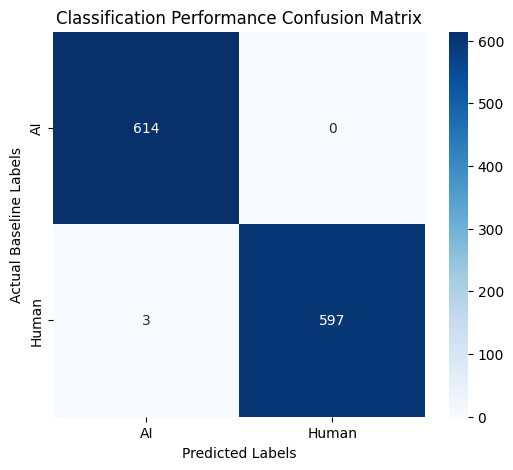

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully.
Model, tokenizer and labels saved successfully!

=== AI Sample Prediction ===
AI

=== Human Sample Prediction ===
AI


In [5]:
# =====================================================================
# STEP 1: IMPORT REQUIRED LIBRARIES AND LOAD DATA
# =====================================================================
import os
import pandas as pd
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

# load file
#'/content/data_for_preprocessing.csv'
df = pd.read_csv('/content/drive/MyDrive/data_for_preprocessing.csv')
# Clean dataset
df = df[["Text", "Author"]].dropna()
df["Text"] = df["Text"].astype(str)
df = df[df["Text"].str.strip() != ""]

# Encode labels (AI -> 0, Human -> 1 or vice-versa)
encoder = LabelEncoder()
df["label"] = encoder.fit_transform(df["Author"])

# Print dataset distribution
print(df["Author"].value_counts())
print(df.head())

# Split data into training and validation
X_train, X_test, y_train, y_test = train_test_split(
    df["Text"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

# =====================================================================
# STEP 2: TOKENIZATION AND DATASET PREPARATION
# =====================================================================
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

train_encodings = tokenizer(X_train, truncation=True, padding=True, max_length=256)
test_encodings = tokenizer(X_test, truncation=True, padding=True, max_length=256)



class TextDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = TextDataset(train_encodings, y_train)
test_dataset = TextDataset(test_encodings, y_test)

# =====================================================================
# STEP 3: INITIALIZE MODEL AND CONFIGURATIONS
# =====================================================================
model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    report_to="none",
    save_strategy="no"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)


trainer.train()

# =====================================================================
# STEP 4: EVALUATE THE MODEL ON TEST Data
# =====================================================================
# Generate predictions for the validation split
predictions = trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)

# Display final classification precision and recall metrics
print("\n=== Final Model Performance Evaluation ===")
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

# Plot Confusion Matrix Graph
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Baseline Labels")
plt.title("Classification Performance Confusion Matrix")
plt.show()
# =======================================================
# STEP 5: FIXED CUSTOM INFERENCE UTILITY FUNCTION
# =======================================================

def predict_text(text):
    # Inputs tokenize
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=256)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Model optimizer
    with torch.no_grad():
        output = model(**inputs)
        logits = output.logits

    predicted_class_id = torch.argmax(logits, dim=1).item()

    # Label decode
    predicted_label = encoder.inverse_transform([predicted_class_id])[0]

    return predicted_label



#   Save  the Model  or  Tokenizer safely
model.save_pretrained("./ai_detector_model")
tokenizer.save_pretrained("./ai_detector_model")
print("Model and tokenizer saved successfully.")

import json

labels_map = {
    int(i): str(label)
    for i, label in enumerate(encoder.classes_)
}

with open("./ai_detector_model/labels.json", "w") as f:
    json.dump(labels_map, f)

print("Model, tokenizer and labels saved successfully!")

# Define sample

ai_sample = "Artificial intelligence is rapidly transforming the landscape of modern technology. By leveraging..."
human_sample = "Honestly, I feel like everyone is talking about AI these days, but it's kind of overhyped. Don't..."


print("\n=== AI Sample Prediction ===")
print(predict_text(ai_sample))

print("\n=== Human Sample Prediction ===")
print(predict_text(human_sample))


In [ ]:
# install streamlit
!pip install streamlit -q

In [ ]:

%%writefile app.py

import streamlit as st
import torch
import json
import os

from transformers import AutoTokenizer, AutoModelForSequenceClassification

# ============================================================
# 1. PAGE SETUP
# ============================================================

st.set_page_config(
    page_title="AI vs Human Text Detector",
    page_icon="🤖",
    layout="centered"
)

st.title("🤖 AI vs 👤 Human Text Detector")

st.subheader(
    "Determine if a paragraph was generated by AI or written by a human."
)

st.write(
    "This app uses a fine-tuned DistilBERT classification model."
)

# ============================================================
# 2. LOAD MODEL AND TOKENIZER
# ============================================================

@st.cache_resource
def load_classification_model():

    model_directory = "./ai_detector_model"

    # Load tokenizer
    tokenizer = AutoTokenizer.from_pretrained(model_directory)

    # Load trained model
    model = AutoModelForSequenceClassification.from_pretrained(
        model_directory
    )

    # Select device
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model.to(device)
    model.eval()

    # Load actual training labels
    labels_path = os.path.join(model_directory, "labels.json")

    with open(labels_path, "r", encoding="utf-8") as f:
        labels_map = json.load(f)

    labels_map = {
        int(key): value for key, value in labels_map.items()
    }

    return tokenizer, model, device, labels_map


# Load saved artifacts
try:

    tokenizer, model, device, labels_map = load_classification_model()

    st.success("Model loaded successfully!")

except Exception as e:

    st.error(f"Model loading error: {e}")

    st.stop()


# ============================================================
# 3. USER INPUT
# ============================================================

st.write("### Paste Your Input Text Below")

user_input = st.text_area(
    label="Enter your text here (maximum 256 tokens):",
    placeholder="Type or paste your paragraph here...",
    height=200
)


# ============================================================
# 4. PREDICT AI OR HUMAN
# ============================================================

if st.button("Analyze Text", type="primary"):

    if user_input.strip() == "":

        st.warning("Please enter some text before analyzing.")

    else:

        with st.spinner("Analyzing your text..."):

            # Tokenize input
            inputs = tokenizer(
                user_input,
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=256
            )

            # Move inputs to same device as model
            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }

            # Model prediction
            with torch.no_grad():

                outputs = model(**inputs)

            # Get predicted class
            predicted_class_id = torch.argmax(
                outputs.logits,
                dim=-1
            ).item()

            # Convert class ID into actual label
            predicted_label = labels_map.get(
                predicted_class_id,
                "Unknown Class"
            )

            # Display result
            st.write("### Classification Output:")

            if "AI" in predicted_label.upper():

                st.error(f"Prediction: {predicted_label}")

            else:

                st.success(f"Prediction: {predicted_label}")

            st.caption(
                "This prediction is an estimate from the trained model, "
                "not a guaranteed determination of authorship."
            )

In [ ]:
%%writefile requirements.txt

streamlit
torch
transformers
safetensors

In [ ]:
# This cell previously contained raw output text and can be safely ignored or deleted.
# Writing /content/requirements.txt

In [ ]:
import os

print(os.listdir("/content/ai_detector_model") if os.path.exists("/content/ai_detector_model") else "Model folder not found")

In [ ]:
import os

print(os.listdir("/content/ai_detector_model") if os.path.exists("/content/ai_detector_model") else "Model folder not found")

In [ ]:
import os
import json

# Define the absolute directory path
target_dir = "/content/ai_detector_model"
os.makedirs(target_dir, exist_ok=True)

# Save model and tokenizer explicitly to the target directory
model.save_pretrained(target_dir)
tokenizer.save_pretrained(target_dir)

# Save the labels mapping to the target directory
labels_map = {
    int(i): str(label)
    for i, label in enumerate(encoder.classes_)
}

with open(os.path.join(target_dir, "labels.json"), "w") as f:
    json.dump(labels_map, f)

print(f"Successfully saved model, tokenizer, and labels to: {target_dir}")
print("Directory contents:", os.listdir(target_dir))

In [ ]:
import os
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_directory = "/content/ai_detector_model"

print("=== Step 1: Checking Directory Contents ===")
if os.path.exists(model_directory):
    files = os.listdir(model_directory)
    print(f"Directory '{model_directory}' exists with files:")
    for file in files:
        print(f" - {file}")

    # Check for core files
    expected_files = ['config.json', 'model.safetensors', 'tokenizer_config.json', 'labels.json']
    missing_files = [f for f in expected_files if f not in files]
    if not missing_files:
        print("\u2705 All expected files are present.")
    else:
        print(f"\u26a0\ufe0f Missing files: {missing_files}")
else:
    print(f"\u274c Directory '{model_directory}' does not exist!")

print("\n=== Step 2: Testing Artifact Loading ===")
try:
    # Load tokenizer
    test_tokenizer = AutoTokenizer.from_pretrained(model_directory)
    # Load model
    test_model = AutoModelForSequenceClassification.from_pretrained(model_directory)
    print("\u2705 Model and Tokenizer loaded back successfully without errors!")
except Exception as e:
    print(f"\u274c Failed to load artifacts: {e}")

In [6]:
import shutil
from google.colab import files

# Zip the model directory
shutil.make_archive('/content/ai_detector_model', 'zip', '/content/ai_detector_model')

# Download the zip file to your local computer
files.download('/content/ai_detector_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>